        # Lesson 7.2 · Preparing Time-Series Data
        ### Datetime indexes, gaps, resampling, rolling windows, lags and seasonal features

        | | |
        |---|---|
        | ⏱️ **Time** | about 90 minutes |
        | 📚 **Before you start** | Lesson 7.1 |
        | 🧪 **Format** | lesson → worked examples → exercises with hints → recap |

        ## 🎯 What you will be able to do after this notebook
        - Turn a raw table of dates into a proper **DatetimeIndex** and slice it by time
- Find and repair **missing timestamps** and **outliers** without leaking the future
- **Resample** and convert frequency (daily → weekly → monthly, and back)
- Build **rolling statistics**, **lag features** and **seasonal features**
- Assemble a clean, *leak-free* modelling table

> 🌾 **The story so far.** The market clerk's spreadsheet arrives: Sundays missing, a washed-out road left a three-week hole, and someone typed 6.2 instead of 62. *"Garbage in, garbage forecast,"* as my own professor used to say.

In [1]:
import sys, pathlib, warnings
# Find the course folder (works no matter where Jupyter was started)
ROOT = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents] if (p / "src" / "agrilab.py").exists())
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import agrilab as ag          # our helper library: src/agrilab.py


warnings.filterwarnings("ignore")   # (after imports: statsmodels re-enables its own warnings when imported)
ag.setup_plots()
ag.set_seed(42)
print("Setup complete. Course folder:", ROOT.name)

Setup complete. Course folder: course


## 1 · Datetime indexing: teaching pandas that dates are dates

Out of the box, a CSV date column is just **text**. Text can't be sliced by month, resampled, or shifted by "one week".
The first move in *every* time-series project:

1. parse to `datetime64`,
2. `set_index` to the date,
3. `sort_index`,
4. check for **duplicates** and **frequency**.

In [2]:
raw = pd.read_csv(ag.DATA / "market_prices_daily.csv")          # NOT parsed on purpose
print(raw.dtypes, "\n")

df = raw.copy()
df["date"] = pd.to_datetime(df["date"])
df = df.sort_values("date")
print("date dtype now:", df["date"].dtype)

hl = df[(df.market == "Highland") & (df.commodity == "tomato")].set_index("date")
print("index monotonic?", hl.index.is_monotonic_increasing, "| duplicates:", hl.index.duplicated().sum())
hl.head(3)

date                 str
market               str
commodity            str
price_per_kg     float64
volume_tonnes    float64
fuel_index       float64
dtype: object 

date dtype now: datetime64[us]
index monotonic? True | duplicates: 0


,market,commodity,price_per_kg,volume_tonnes,fuel_index
date,,,,,
2015-01-01,Highland,tomato,57.13,86.5,100.4
2015-01-02,Highland,tomato,58.66,120.7,101.1
2015-01-03,Highland,tomato,56.17,93.6,101.6


With a `DatetimeIndex`, slicing becomes delightful: partial-string indexing:

In [3]:
print(hl.loc["2020-03":"2020-04", "price_per_kg"].describe().round(1))      # whole months by name
print("\nDay of week of first rows:", hl.index.day_name()[:3].tolist())
print("Inferred frequency:", pd.infer_freq(hl.index))                      # None -> the series is irregular!

count     50.0
mean     148.0
std       13.2
min      121.0
25%      135.2
50%      152.1
75%      158.2
max      171.2
Name: price_per_kg, dtype: float64

Day of week of first rows: ['Thursday', 'Friday', 'Saturday']
Inferred frequency: None


> 💡 **Professor's aside.** `infer_freq` returning `None` is pandas telling you *"this isn't a regular series yet"*. Most statistical models need regular spacing.

---
### 🧩 Exercise 1: Datetime detective  ⭐

For the **Highland tomato** series (`hl` above), measure how many holes it has:
- `n_missing_days`: how many **calendar days** between the first and last date have no record at all
  (Sundays count; the market is closed, but the calendar still has them).
- `longest_gap`: the longest run of **consecutive** missing calendar days.

<details><summary>💡 Hint 1: gentle nudge</summary>

Build the complete calendar with `pd.date_range(hl.index.min(), hl.index.max(), freq='D')`.

</details>

<details><summary>💡 Hint 2: bigger nudge</summary>

`full.difference(hl.index)` gives the dates that are in the calendar but not in the data. Its length is `n_missing_days`.

</details>

<details><summary>💡 Hint 3: almost the answer</summary>

For the longest run: sort the missing dates, then look at day-to-day differences. A new run starts whenever the difference isn't exactly 1 day. `groupby` on the cumulative sum of those 'run starts', then take the largest group size.

</details>

<details><summary>💡 Hint 4: full walkthrough</summary>

`miss = pd.Series(missing_dates); run_id = (miss.diff().dt.days != 1).cumsum(); longest_gap = miss.groupby(run_id).size().max()`

</details>

*Write your answer in the next cell, then run the check cell below it. Stuck after the hints? The full solution is in `solutions/`.*

In [ ]:
full = None
missing_dates = None
n_missing_days = None
longest_gap = None

In [ ]:
try:
    exp_missing = len(pd.date_range(hl.index.min(), hl.index.max()).difference(hl.index))
    ag.check("n_missing_days is right", n_missing_days == exp_missing, "len(full.difference(index))")
    ag.check("longest_gap found the 2017 road washout (>= 19 days)", longest_gap is not None and longest_gap >= 19,
             "consecutive missing dates differ by exactly 1 day")
except Exception as _e:
    print('\u23f3 Not ready yet: finish the exercise cell above, then re-run this check.  (' + type(_e).__name__ + ': ' + str(_e)[:90] + ')')

---
## 2 · Missing timestamps: three kinds of "missing"

| Kind | Example here | Honest treatment |
|---|---|---|
| **Structural** | Sundays – market closed | Often *not* an error: choose a business-day or weekly frequency, or carry the last price |
| **Random** | clerk forgot to record | Short gaps: interpolate |
| **Outage** | 19-day road washout | Long gaps: interpolate cautiously, add an `is_imputed` flag, or let the model handle NaN |

First **reindex** to a full calendar so the gaps become visible NaNs, then choose a fill rule.
But which rule? *Don't guess: run an experiment.* We hide 8 % of values we actually know, fill them with each method,
and see who recovers the truth best.

In [6]:
obs = ag.load_prices("tomato", "Central").set_index("date")["price_per_kg"]
rng = np.random.default_rng(1)
hide = rng.choice(obs.index[400:], size=int(0.08 * len(obs)), replace=False)   # keep 1st year intact (needed for seasonal fill)
masked = obs.copy(); masked.loc[hide] = np.nan

cal = pd.date_range(obs.index.min(), obs.index.max(), freq="D")
m = masked.reindex(cal)                                            # gaps are now explicit NaN
candidates = {
    "forward fill (carry last)": m.ffill(),
    "backward fill (LEAKS future!)": m.bfill(),
    "linear interpolation": m.interpolate("linear"),
    "time-weighted interpolation": m.interpolate("time"),
    "same day last year": m.fillna(m.shift(364)),
}
rows = {name: ag.mae(obs.loc[hide], filled.loc[hide].fillna(obs.mean())) for name, filled in candidates.items()}
pd.Series(rows, name="MAE on hidden values").sort_values().round(3).to_frame()

,MAE on hidden values
time-weighted interpolation,1.864
linear interpolation,1.864
forward fill (carry last),2.603
backward fill (LEAKS future!),2.726
same day last year,20.929


Interpolation wins for short random gaps, but note that **backward fill and any interpolation use the future**.
That's perfectly fine for *cleaning history before you split the data*, but inside a live forecasting loop
you may only fill with **past** information (forward fill). Keep that distinction in your head; it returns in Lesson 7.3.

### Outliers: the decimal slip
Somebody typed a price ten times too large. A robust detector compares each value to a *rolling median* (medians ignore the odd one out):

              market commodity  price_per_kg  rolling_median
date                                                        
2016-05-10  Highland    tomato        714.30            74.7
2018-02-01  Highland    tomato          6.76            66.4
2020-02-08  Highland    tomato       1058.40           105.3
2023-11-03  Highland    tomato       1022.90           100.0
2024-03-23  Highland    tomato       1655.30           176.4


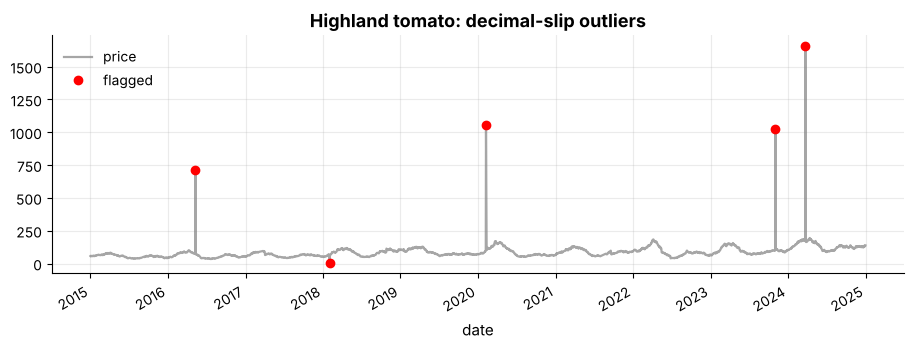

In [7]:
p = hl["price_per_kg"]
med = p.rolling(31, center=True, min_periods=5).median()
ratio = p / med
flagged = hl[(ratio > 3) | (ratio < 1 / 3)]
print(flagged[["market", "commodity", "price_per_kg"]].assign(rolling_median=med[flagged.index].round(1)))

ax = p.plot(figsize=(11, 3.5), color="gray", alpha=.7, label="price")
flagged["price_per_kg"].plot(style="ro", ax=ax, label="flagged"); ax.legend(); ax.set_title("Highland tomato: decimal-slip outliers"); plt.show()

> 💡 **Professor's aside.** A *centered* window peeks at the future: acceptable for **cleaning** a finished history, forbidden for **features** you'd compute live. When in doubt ask: *"Would I know this at the moment of the forecast?"*

---
### 🧩 Exercise 2: Outlier hunter  ⭐⭐

There are decimal-slip errors hiding in the **Highland** market across **all four commodities**.
Load `ag.load_prices(market="Highland")`, and for each commodity separately compute the 31-observation centered rolling
median. Flag rows where the price is above **3×** or below **1/3** of that median.
Store the flagged rows in `outliers` and their count in `n_outliers`.

<details><summary>💡 Hint 1: gentle nudge</summary>

You need the rolling median *within each commodity*: `df.groupby('commodity')['price_per_kg'].transform(...)`.

</details>

<details><summary>💡 Hint 2: bigger nudge</summary>

Inside transform: `lambda s: s.rolling(31, center=True, min_periods=5).median()`.

</details>

<details><summary>💡 Hint 3: almost the answer</summary>

`bad = (df.price_per_kg > 3 * df.med) | (df.price_per_kg < df.med / 3)` then `outliers = df[bad]`.

</details>

*Write your answer in the next cell, then run the check cell below it. Stuck after the hints? The full solution is in `solutions/`.*

In [ ]:
hl_all = ag.load_prices(market="Highland")
# hl_all["med"] = ...
outliers = None
n_outliers = None

In [ ]:
try:
    ag.check("found exactly the 7 planted decimal slips", n_outliers == 7, "3x above / 1/3 below the rolling median, per commodity")
    ag.check("every flagged value is wildly off its median",
             (np.maximum(outliers.price_per_kg / outliers.med, outliers.med / outliers.price_per_kg) > 3).all())
except Exception as _e:
    print('\u23f3 Not ready yet: finish the exercise cell above, then re-run this check.  (' + type(_e).__name__ + ': ' + str(_e)[:90] + ')')

---
## 3 · Resampling & frequency conversion

Markets report daily, but a cooperative plans monthly. **Resampling** changes the sampling frequency.

| Direction | Question you must answer | Typical tools |
|---|---|---|
| **Down-sampling** (daily → weekly) | *How do I summarise many values into one?* | `mean`, `sum`, `last`, `min/max` |
| **Up-sampling** (monthly → daily) | *What do I put in the new empty slots?* | `ffill`, `interpolate` |

The aggregation must match the *meaning* of the column: **prices → mean** (or last), **volumes → sum**.

| Alias | Meaning | | Alias | Meaning |
|---|---|---|---|---|
| `D` | calendar day | | `ME` | month end (older pandas: `M`) |
| `B` | business day | | `MS` | month start |
| `W` / `W-FRI` | week ending Sunday / Friday | | `QE`, `YE` | quarter / year end |

            avg_price  total_volume_t
date                                 
2024-10-31      141.3           946.5
2024-11-30      139.9           973.7
2024-12-31      151.9           804.6


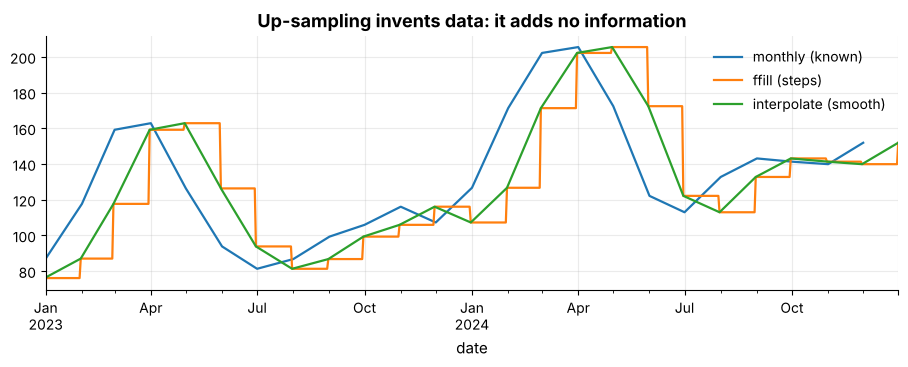

In [10]:
cen = ag.load_prices("tomato", "Central").set_index("date")
monthly = cen.resample("ME").agg({"price_per_kg": "mean", "volume_tonnes": "sum"})
monthly.columns = ["avg_price", "total_volume_t"]
print(monthly.tail(3).round(1))

# Up-sampling: monthly -> daily. Two ways to fill the new slots.
up = monthly["avg_price"].resample("D")
ffilled, interp = up.ffill(), up.interpolate("time")
ax = monthly["avg_price"]["2023":].plot(style="ko", figsize=(11, 3.3), label="monthly (known)")
ffilled["2023":].plot(ax=ax, label="ffill (steps)"); interp["2023":].plot(ax=ax, label="interpolate (smooth)")
ax.legend(); ax.set_title("Up-sampling invents data: it adds no information"); plt.show()

> ⚠️ **Common pitfall.** `asfreq()` only *selects* timestamps (values on other days become NaN); `resample()` *aggregates*. Using the wrong one silently throws away data.

> 🤔 **Pause and think.** Why is summing prices over a month a mistake, but summing volumes is fine?
>
> <details><summary>Click to reveal the answer</summary>
>
> Volume is an *amount per period* (it adds up. A price is a *rate/level*) adding twelve prices gives nonsense; average (or take the last) instead.
>
> </details>

---
### 🧩 Exercise 3: Pivot and resample  ⭐⭐

Using the **Central** market only:
1. Pivot to a *wide* table with one column per commodity and the **daily price** as values (index = date).
2. Resample that wide table to **month-end mean** prices. Call the result `monthly_wide`.
3. Compute `monthly_volume`: total monthly **volume** (sum) per commodity, also wide.

<details><summary>💡 Hint 1: gentle nudge</summary>

`df.pivot_table(index='date', columns='commodity', values='price_per_kg')` makes the wide table.

</details>

<details><summary>💡 Hint 2: bigger nudge</summary>

Then `.resample('ME').mean()`.

</details>

<details><summary>💡 Hint 3: almost the answer</summary>

Same pivot but `values='volume_tonnes'` and `.resample('ME').sum()`.

</details>

*Write your answer in the next cell, then run the check cell below it. Stuck after the hints? The full solution is in `solutions/`.*

In [ ]:
central = ag.load_prices(market="Central")
monthly_wide = None
monthly_volume = None

In [ ]:
try:
    ag.check("monthly_wide is 120 months x 4 crops", getattr(monthly_wide, "shape", None) == (120, 4))
    ag.check("columns are the 4 commodities", set(getattr(monthly_wide, "columns", [])) == set(ag.COMMODITIES))
    ag.check("volume was SUMMED (much larger than any single day)", monthly_volume is not None and monthly_volume.max().max() > 1500)
except Exception as _e:
    print('\u23f3 Not ready yet: finish the exercise cell above, then re-run this check.  (' + type(_e).__name__ + ': ' + str(_e)[:90] + ')')

---
## 4 · Rolling statistics: the "recent past" summarised

A **rolling window** slides along the series, computing a statistic over the last *w* observations.
It smooths noise (moving average), tracks local volatility (rolling std), and (crucially) creates
**features** for ML models.

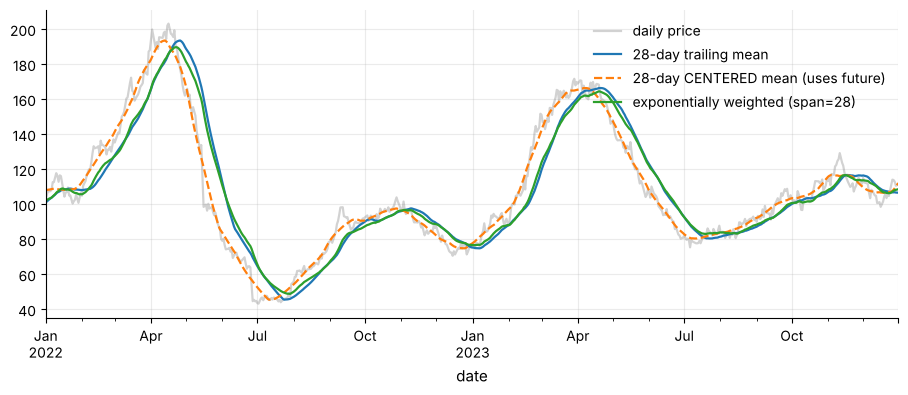

In [13]:
t = ag.price_series("tomato", "Central", "D")
fig, ax = plt.subplots(figsize=(11, 4))
t["2022":"2023"].plot(ax=ax, alpha=.35, color="gray", label="daily price")
t.rolling("28D").mean()["2022":"2023"].plot(ax=ax, label="28-day trailing mean")
t.rolling(28, center=True).mean()["2022":"2023"].plot(ax=ax, ls="--", label="28-day CENTERED mean (uses future)")
t.ewm(span=28).mean()["2022":"2023"].plot(ax=ax, label="exponentially weighted (span=28)")
ax.legend(); plt.show()

**Trailing** (default) windows look *backward* (safe for forecasting. **Centered** windows look both ways) nice charts,
but a forecasting model fed a centered mean is quietly cheating. **EWM** gives recent points more weight (we'll meet it again as *exponential smoothing*).

---
## 5 · Lag features & seasonal features

To let a plain regression model "see" time, we turn the series into a table:

| target `y_t` | `lag_1` | `lag_2` | `lag_52` | `rmean_4` | `month_sin` | `month_cos` |
|---|---|---|---|---|---|---|

Every column must be **knowable at forecast time**. The golden rule: **shift first, then roll.**
`y.shift(1).rolling(4).mean()` = mean of the four weeks *before* today. `y.rolling(4).mean()` *includes today*: a leak when today is the target.

**Seasonal features** encode the calendar: month, week of year, day of week. But `month = 12` and `month = 1` are numerically far apart
while being neighbours on the calendar. Fix: place the month on a **circle**:
$$\text{month\_sin} = \sin\!\left(\tfrac{2\pi\, m}{12}\right),\qquad \text{month\_cos} = \cos\!\left(\tfrac{2\pi\, m}{12}\right)$$

raw distance Dec-Jan: 11   | circle distance Dec-Jan: 0.52   | circle distance Dec-Jun: 2.00


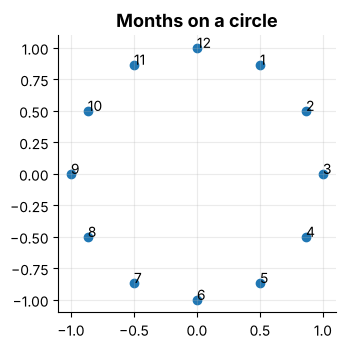

In [14]:
months = np.arange(1, 13)
ms, mc = np.sin(2 * np.pi * months / 12), np.cos(2 * np.pi * months / 12)
dist = lambda a, b: np.hypot(ms[a-1] - ms[b-1], mc[a-1] - mc[b-1])
print(f"raw distance Dec-Jan: {abs(12-1)}   | circle distance Dec-Jan: {dist(12,1):.2f}   | circle distance Dec-Jun: {dist(12,6):.2f}")
fig, ax = plt.subplots(figsize=(3.6, 3.6)); ax.scatter(ms, mc); [ax.annotate(m, (x, y)) for m, x, y in zip(months, ms, mc)]
ax.set_aspect("equal"); ax.set_title("Months on a circle"); plt.show()

---
### 🧩 Exercise 4: Encode a month as a point on a circle  ⭐

Write `encode_month(m)` returning a tuple `(sin, cos)` for month number `m` (1-12), using the formulas above.
Then compute `d_dec_jan` and `d_dec_jun`: Euclidean distances between the encodings of those month pairs.

<details><summary>💡 Hint 1: gentle nudge</summary>

`angle = 2 * np.pi * m / 12`

</details>

<details><summary>💡 Hint 2: bigger nudge</summary>

return `(np.sin(angle), np.cos(angle))`

</details>

<details><summary>💡 Hint 3: almost the answer</summary>

`np.hypot(a[0]-b[0], a[1]-b[1])` is the distance between two points a and b.

</details>

*Write your answer in the next cell, then run the check cell below it. Stuck after the hints? The full solution is in `solutions/`.*

In [ ]:
def encode_month(m):
    # your code
    return None

d_dec_jan = None
d_dec_jun = None

In [ ]:
try:
    ag.check("December is close to January", d_dec_jan is not None and d_dec_jan < 0.6)
    ag.check("December is far from June", d_dec_jun is not None and d_dec_jun > 1.9)
    ag.check("12 and 0 map to the same point", np.allclose(encode_month(12), encode_month(0)))
except Exception as _e:
    print('\u23f3 Not ready yet: finish the exercise cell above, then re-run this check.  (' + type(_e).__name__ + ': ' + str(_e)[:90] + ')')

### Exogenous drivers: rain today, price in two months
Prices respond to *outside* variables. Rainfall is a supply signal: heavy rain now → bigger harvest roughly two months later → softer prices.
Let's join weather onto the weekly price and look at the lagged relationship.

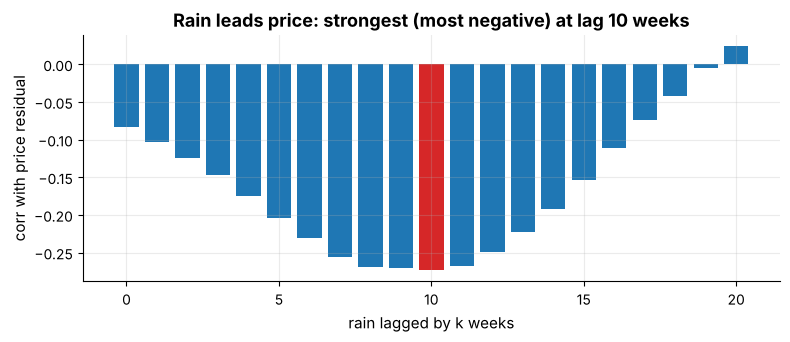

In [17]:
from statsmodels.tsa.seasonal import STL
wk = ag.price_series("tomato", "Central", "W")
resid = STL(np.log(wk), period=52, robust=True).fit().resid          # price movement NOT explained by trend/season
rain = ag.load_weather().set_index("date")["rainfall_mm"].resample("W").sum().reindex(wk.index)
rain_60d = rain.rolling(9, min_periods=1).sum()                       # ~60 days of accumulated rain

corr = {lag: resid.corr(rain_60d.shift(lag)) for lag in range(0, 21)}
best = min(corr, key=corr.get)
plt.figure(figsize=(9, 3.2)); plt.bar(corr.keys(), corr.values(), color=["tab:red" if k == best else "tab:blue" for k in corr])
plt.xlabel("rain lagged by k weeks"); plt.ylabel("corr with price residual"); plt.title(f"Rain leads price: strongest (most negative) at lag {best} weeks"); plt.show()

A cross-correlation like this is how you *discover* useful lags for SARIMAX or ML features, instead of guessing.

---
## 6 · Putting it together: a leak-free modelling table

Now a real build. For weekly Central tomato prices, create a DataFrame whose row *t* has:
- target `y` (price in week *t*),
- lag features `lag_1`, `lag_2`, `lag_4`, `lag_52`,
- trailing rolling features `rmean_4`, `rmean_13` (**shifted first!**),
- calendar features `month_sin`, `month_cos`.

---
### 🧩 Exercise 5: Build the feature table: without leaking  ⭐⭐⭐

Write `build_features(y)` for a weekly price Series `y` (DatetimeIndex) that returns a DataFrame with columns:
`y, lag_1, lag_2, lag_4, lag_52, rmean_4, rmean_13, month_sin, month_cos`
(any order, then `y` first). **Every feature in row *t* must use only values from weeks before *t*.**
Drop rows with NaN at the end. Call it on `wk` and store the result in `feat`.

<details><summary>💡 Hint 1: gentle nudge</summary>

Start with `out = pd.DataFrame({'y': y})`, then add `out['lag_1'] = y.shift(1)` and so on.

</details>

<details><summary>💡 Hint 2: bigger nudge</summary>

Rolling features: `out['rmean_4'] = y.shift(1).rolling(4).mean()`: the `shift(1)` comes **before** `rolling`.

</details>

<details><summary>💡 Hint 3: almost the answer</summary>

Calendar: `out['month_sin'] = np.sin(2*np.pi*y.index.month/12)` and the cosine. Calendar features of week *t* are knowable in advance, so they don't leak.

</details>

<details><summary>💡 Hint 4: full walkthrough</summary>

Finish with `return out.dropna()`.

</details>

*Write your answer in the next cell, then run the check cell below it. Stuck after the hints? The full solution is in `solutions/`.*

In [ ]:
def build_features(y):
    out = pd.DataFrame({"y": y})
    # lags...
    # rolling (shift first!)...
    # calendar...
    return out.dropna()

feat = build_features(wk)

In [ ]:
try:
    need = {"y", "lag_1", "lag_2", "lag_4", "lag_52", "rmean_4", "rmean_13", "month_sin", "month_cos"}
    ag.check("all required columns exist", need.issubset(set(feat.columns)))
    i = 100; t = feat.index[i]; loc = wk.index.get_loc(t)
    ag.check("lag_1 is last week's price", np.isclose(feat.loc[t, "lag_1"], wk.iloc[loc - 1]))
    ag.check("rmean_4 averages the 4 weeks BEFORE t (not including t)", np.isclose(feat.loc[t, "rmean_4"], wk.iloc[loc - 4:loc].mean()),
             "y.shift(1).rolling(4).mean()")
    # leak detector: wreck the final observation; its own features must not change
    y2 = wk.copy(); y2.iloc[-1] = 1e6
    ag.check("LEAK TEST: changing the last price does not change the last row's features",
             np.allclose(build_features(y2).drop(columns="y").iloc[-1], build_features(wk).drop(columns="y").iloc[-1]))
except Exception as _e:
    print('\u23f3 Not ready yet: finish the exercise cell above, then re-run this check.  (' + type(_e).__name__ + ': ' + str(_e)[:90] + ')')

That leak test is worth stealing for your own projects: *corrupt the target, rebuild the features; if any feature changed, you have a leak.*

The course library includes a generalised version, `ag.make_ts_features(y, lags=..., roll_windows=..., horizon=..., exog=...)`,
which refuses lags shorter than the forecast horizon. We'll use it in Lesson 7.6.

In [20]:
ag.make_ts_features(wk, lags=(1, 2, 4, 52), roll_windows=(4, 13), exog=pd.DataFrame({"rain_60d": rain_60d})).dropna().head(3).round(2).T

date,2016-01-03,2016-01-10,2016-01-17
y,53.15,53.77,53.64
lag_1,51.77,53.15,53.77
lag_2,48.84,51.77,53.15
lag_4,53.32,47.62,48.84
lag_52,65.47,65.12,63.61
rmean_4,50.39,50.34,51.88
rstd_4,2.62,2.56,2.20
rmean_13,58.37,57.64,56.52
rstd_13,6.79,6.80,6.05
month,1.00,1.00,1.00


        ---
        ## 🧾 Recap
        - `to_datetime` → `set_index` → `sort_index` → check duplicates & frequency.
- Reindex to a full calendar to *see* gaps; choose fill rules by **experiment**, not habit.
- Resample with aggregations that match meaning (price→mean, volume→sum). Up-sampling adds no information.
- **Shift first, then roll.** Trailing windows are safe; centered windows are for cleaning only.
- Encode cyclic calendar features on a circle; add exogenous drivers at *lags* that make physical sense.
- Always run a **leak test** on your feature builder.

**Next up:** Lesson 7.3: how to measure a forecast honestly: metrics, baselines, and walk-forward validation.